# TP API
---

##### Realizar una petición GET al sitio web de la UNO y mostrar el código de respuesta.

In [5]:
import requests
from unittest.mock import patch, Mock


def obtener_status(url):
    r = requests.get(url)
    return r.status_code


def test_obtener_status_ok():
    respuesta_falsa = Mock()
    respuesta_falsa.status_code = 200

    with patch("requests.get", return_value=respuesta_falsa):
        resultado = obtener_status("https://www.un.org")

    assert resultado == 200


def test_obtener_status_error():
    respuesta_falsa = Mock()
    respuesta_falsa.status_code = 404

    with patch("requests.get", return_value=respuesta_falsa):
        resultado = obtener_status("https://www.un.org/no-existe")

    assert resultado == 404

##### Realizar una petición GET a https://httpbin.org/get y mostrar:
* código de estado
* URL de la respuesta
* contenido en texto

In [4]:
import requests

res = requests.get("https://httpbin.org/get")

print("Código de estado:", res.status_code)
print("URL de la respuesta:", res.url)

texto = res.text
print("Contenido en texto:", texto)

Código de estado: 200
URL de la respuesta: https://httpbin.org/get
Contenido en texto: {
  "args": {}, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6ac8068c-4474c21d47a1d554049a8190"
  }, 
  "origin": "186.158.2.222", 
  "url": "https://httpbin.org/get"
}



##### Enviar parámetros en la consulta (?nombre=Juan&edad=30) y verificar que el servidor los reciba.

In [5]:
import requests

params = {
    "nombre": "Juan",
    "edad": 30
}

res = requests.get("https://httpbin.org/get", params=params)

print("URL:", res.url)
print("Respuesta:")
print(res.text)

URL: https://httpbin.org/get?nombre=Juan&edad=30
Respuesta:
{
  "args": {
    "edad": "30", 
    "nombre": "Juan"
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6ac8068f-747de8c13b78e00a5f655722"
  }, 
  "origin": "186.158.2.222", 
  "url": "https://httpbin.org/get?nombre=Juan&edad=30"
}



##### Enviar un formulario (json) con POST a https://httpbin.org/post y muestra la respuesta.

In [6]:
import requests

datos = {
    "nombre": "Juan",
    "edad": 30
}

res = requests.post(
    "https://httpbin.org/post",
    json=datos
)

print("Código de estado:", res.status_code)
print("Respuesta:")
print(res.text)

Código de estado: 200
Respuesta:
{
  "args": {}, 
  "data": "{\"nombre\": \"Juan\", \"edad\": 30}", 
  "files": {}, 
  "form": {}, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate", 
    "Content-Length": "30", 
    "Content-Type": "application/json", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6ac80694-0ab9c63957d689c0041bfdc0"
  }, 
  "json": {
    "edad": 30, 
    "nombre": "Juan"
  }, 
  "origin": "186.158.2.222", 
  "url": "https://httpbin.org/post"
}



##### Enviar una cabecera personalizada (User-Agent) y comprueba que el servidor la reciba.

In [7]:
import requests

headers = {
    "User-Agent": "MiProgramaPython/1.0"
}

res = requests.get(
    "https://httpbin.org/headers",
    headers=headers
)

print("Código de estado:", res.status_code)
print("Respuesta:")
print(res.text)

Código de estado: 200
Respuesta:
{
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate", 
    "Host": "httpbin.org", 
    "User-Agent": "MiProgramaPython/1.0", 
    "X-Amzn-Trace-Id": "Root=1-6ac80697-03cd272532f2bfdd6939d185"
  }
}



##### Descargar una imagen (https://httpbin.org/image/png) y guardarla en su disco.

In [8]:
import requests

url = "https://httpbin.org/image/png"

res = requests.get(url)

if res.status_code == 200:
    with open("imagen.png", "wb") as archivo:
        archivo.write(res.content)

    print("Imagen descargada correctamente.")
else:
    print("Error al descargar la imagen:", res.status_code)

Imagen descargada correctamente.


##### Enviar una cookie (https://httpbin.org/cookies) y verificar que el servidor la reciba.

In [9]:
import requests

cookies = {
    "usuario": "Juan"
}

res = requests.get(
    "https://httpbin.org/cookies",
    cookies=cookies
)

print("Código de estado:", res.status_code)
print("Cookies recibidas por el servidor:")
print(res.text)

Código de estado: 200
Cookies recibidas por el servidor:
{
  "cookies": {
    "usuario": "Juan"
  }
}



##### Hacer una petición a https://httpbin.org/redirect/3 y analizar:
* historial (history)
* URL final (url)

In [10]:
import requests

res = requests.get("https://httpbin.org/redirect/3")

print("URL final:", res.url)

print("\nHistorial de redirecciones:")

for i, respuesta in enumerate(res.history, start=1):
    print(f"Redirección {i}:")
    print("  Código:", respuesta.status_code)
    print("  URL:", respuesta.url)

URL final: https://httpbin.org/get

Historial de redirecciones:
Redirección 1:
  Código: 302
  URL: https://httpbin.org/redirect/3
Redirección 2:
  Código: 302
  URL: https://httpbin.org/relative-redirect/2
Redirección 3:
  Código: 302
  URL: https://httpbin.org/relative-redirect/1


##### Hacer una petición a una URL inexistente y usar raise_for_status() para capturar el error.

In [11]:
import requests

try:
    res = requests.get("https://httpbin.org/esta-url-no-existe")

    res.raise_for_status()

    print("La petición fue exitosa.")
    print(res.text)

except requests.exceptions.HTTPError as error:
    print("Se produjo un error HTTP:")
    print(error)

Se produjo un error HTTP:
404 Client Error: NOT FOUND for url: https://httpbin.org/esta-url-no-existe


##### Descargar un archivo grande (https://httpbin.org/stream/5) y procesa su contenido línea por línea con iter_lines().

In [12]:
import requests

res = requests.get(
    "https://httpbin.org/stream/5",
    stream=True
)

res.raise_for_status()

for linea in res.iter_lines():
    if linea:
        print(linea.decode("utf-8"))

{"url": "https://httpbin.org/stream/5", "args": {}, "headers": {"Host": "httpbin.org", "X-Amzn-Trace-Id": "Root=1-6ac806a5-7815bd5c6e81248f7030da0a", "User-Agent": "python-requests/2.34.2", "Accept-Encoding": "gzip, deflate", "Accept": "*/*"}, "origin": "186.158.2.222", "id": 0}
{"url": "https://httpbin.org/stream/5", "args": {}, "headers": {"Host": "httpbin.org", "X-Amzn-Trace-Id": "Root=1-6ac806a5-7815bd5c6e81248f7030da0a", "User-Agent": "python-requests/2.34.2", "Accept-Encoding": "gzip, deflate", "Accept": "*/*"}, "origin": "186.158.2.222", "id": 1}
{"url": "https://httpbin.org/stream/5", "args": {}, "headers": {"Host": "httpbin.org", "X-Amzn-Trace-Id": "Root=1-6ac806a5-7815bd5c6e81248f7030da0a", "User-Agent": "python-requests/2.34.2", "Accept-Encoding": "gzip, deflate", "Accept": "*/*"}, "origin": "186.158.2.222", "id": 2}
{"url": "https://httpbin.org/stream/5", "args": {}, "headers": {"Host": "httpbin.org", "X-Amzn-Trace-Id": "Root=1-6ac806a5-7815bd5c6e81248f7030da0a", "User-Agen

##### Crear una función que consulte una API pública (por ejemplo, https://jsonplaceholder.typicode.com/posts) y:
* Obtenga todos los posts
* Muestre los títulos
* Permita enviar un nuevo post con POST

In [13]:
import requests

URL = "https://jsonplaceholder.typicode.com/posts"


def obtener_posts():
    res = requests.get(URL)
    res.raise_for_status()

    posts = res.json()

    print("Títulos de los posts:\n")

    for post in posts:
        print(f"{post['id']}: {post['title']}")

    return posts


def crear_post(titulo, contenido, usuario_id):
    datos = {
        "title": titulo,
        "body": contenido,
        "userId": usuario_id
    }

    res = requests.post(URL, json=datos)
    res.raise_for_status()

    post = res.json()

    print("\nPost creado:")
    print(post)

    return post


# Obtener todos los posts
posts = obtener_posts()

# Crear un nuevo post
crear_post(
    "Mi nuevo post",
    "Este es el contenido del nuevo post.",
    1
)

Títulos de los posts:

1: sunt aut facere repellat provident occaecati excepturi optio reprehenderit
2: qui est esse
3: ea molestias quasi exercitationem repellat qui ipsa sit aut
4: eum et est occaecati
5: nesciunt quas odio
6: dolorem eum magni eos aperiam quia
7: magnam facilis autem
8: dolorem dolore est ipsam
9: nesciunt iure omnis dolorem tempora et accusantium
10: optio molestias id quia eum
11: et ea vero quia laudantium autem
12: in quibusdam tempore odit est dolorem
13: dolorum ut in voluptas mollitia et saepe quo animi
14: voluptatem eligendi optio
15: eveniet quod temporibus
16: sint suscipit perspiciatis velit dolorum rerum ipsa laboriosam odio
17: fugit voluptas sed molestias voluptatem provident
18: voluptate et itaque vero tempora molestiae
19: adipisci placeat illum aut reiciendis qui
20: doloribus ad provident suscipit at
21: asperiores ea ipsam voluptatibus modi minima quia sint
22: dolor sint quo a velit explicabo quia nam
23: maxime id vitae nihil numquam
24: autem

{'title': 'Mi nuevo post',
 'body': 'Este es el contenido del nuevo post.',
 'userId': 1,
 'id': 101}

##### Buscar información específica usando parámetros GET (ej: buscar en GitHub: https://api.github.com/)

In [21]:
import requests

url = "https://api.github.com/search/repositories"

params = {
    "q": "python",
    "sort": "stars",
    "order": "desc"
}

res = requests.get(url, params=params)
res.raise_for_status()

datos = res.json()

print("Resultados encontrados:", datos["total_count"])
print()

for repositorio in datos["items"][:10]:
    print("Nombre:", repositorio["full_name"])
    print("Descripción:", repositorio["description"])
    print("Estrellas:", repositorio["stargazers_count"])
    print("URL:", repositorio["html_url"])
    print("-" * 50)

Resultados encontrados: 7311064

Nombre: donnemartin/system-design-primer
Descripción: Learn how to design large-scale systems. Prep for the system design interview.  Includes Anki flashcards.
Estrellas: 373440
URL: https://github.com/donnemartin/system-design-primer
--------------------------------------------------
Nombre: vinta/awesome-python
Descripción: The definitive list that answers "I want to do X in Python, which tool should I use?"
Estrellas: 325907
URL: https://github.com/vinta/awesome-python
--------------------------------------------------
Nombre: practical-tutorials/project-based-learning
Descripción: Curated list of project-based tutorials
Estrellas: 286095
URL: https://github.com/practical-tutorials/project-based-learning
--------------------------------------------------
Nombre: TheAlgorithms/Python
Descripción: All Algorithms implemented in Python
Estrellas: 225095
URL: https://github.com/TheAlgorithms/Python
--------------------------------------------------
Nombre

##### Crear una función que utilizando la API swapi (https://swapi.dev/) muestre la lista de personajes, cada vez que muestre la información de una página preguntará si quiere seguir mostrando más personajes. A continuación pedirá el nombre de un personaje y te dará información sobre él.

In [3]:
import requests

def mostrar_personajes():
    url = "https://swapi.dev/api/people/"

    while url:
        try:
            res = requests.get(url, timeout=10)
            res.raise_for_status()
        except requests.exceptions.RequestException as e:
            print(f"\nError al conectar con la API: {e}")
            print("Intentá de nuevo más tarde.")
            return

        datos = res.json()

        print("\n--- PERSONAJES ---")

        for personaje in datos["results"]:
            print(
                f"Nombre: {personaje['name']} | "
                f"Altura: {personaje['height']} | "
                f"Peso: {personaje['mass']}"
            )

        url = datos["next"]

        if url:
            continuar = input("\n¿Querés mostrar más personajes? (s/n): ")
            if continuar.lower() != "s":
                break

    print("\nFin de la lista.")


def buscar_personaje():
    nombre = input("\nIngresá el nombre del personaje: ")

    try:
        res = requests.get(
            "https://swapi.dev/api/people/",
            params={"search": nombre},
            timeout=10
        )
        res.raise_for_status()
    except requests.exceptions.RequestException as e:
        print(f"\nError al conectar con la API: {e}")
        return

    datos = res.json()

    if len(datos["results"]) == 0:
        print("No se encontró ningún personaje.")
        return

    print("\n--- RESULTADOS ---")

    for personaje in datos["results"]:
        print("\nNombre:", personaje["name"])
        print("Altura:", personaje["height"])
        print("Peso:", personaje["mass"])
        print("Color de pelo:", personaje["hair_color"])
        print("Color de piel:", personaje["skin_color"])
        print("Color de ojos:", personaje["eye_color"])
        print("Año de nacimiento:", personaje["birth_year"])
        print("Género:", personaje["gender"])


# Mostrar personajes página por página
mostrar_personajes()

# Buscar un personaje
buscar_personaje()


--- PERSONAJES ---
Nombre: Luke Skywalker | Altura: 172 | Peso: 77
Nombre: C-3PO | Altura: 167 | Peso: 75
Nombre: R2-D2 | Altura: 96 | Peso: 32
Nombre: Darth Vader | Altura: 202 | Peso: 136
Nombre: Leia Organa | Altura: 150 | Peso: 49
Nombre: Owen Lars | Altura: 178 | Peso: 120
Nombre: Beru Whitesun lars | Altura: 165 | Peso: 75
Nombre: R5-D4 | Altura: 97 | Peso: 32
Nombre: Biggs Darklighter | Altura: 183 | Peso: 84
Nombre: Obi-Wan Kenobi | Altura: 182 | Peso: 77

--- PERSONAJES ---
Nombre: Anakin Skywalker | Altura: 188 | Peso: 84
Nombre: Wilhuff Tarkin | Altura: 180 | Peso: unknown
Nombre: Chewbacca | Altura: 228 | Peso: 112
Nombre: Han Solo | Altura: 180 | Peso: 80
Nombre: Greedo | Altura: 173 | Peso: 74
Nombre: Jabba Desilijic Tiure | Altura: 175 | Peso: 1,358
Nombre: Wedge Antilles | Altura: 170 | Peso: 77
Nombre: Jek Tono Porkins | Altura: 180 | Peso: 110
Nombre: Yoda | Altura: 66 | Peso: 17
Nombre: Palpatine | Altura: 170 | Peso: 75

Fin de la lista.


KeyboardInterrupt: Interrupted by user

##### Trabajar con una API pública que le permita obtener datos, con esos datos responder alguna pregunta de interés para procesarlos (usar pandas) y luego hacer una visualización (usar matplotlib).

Primeros registros:
   userId  id                                              title  \
0       1   1  sunt aut facere repellat provident occaecati e...   
1       1   2                                       qui est esse   
2       1   3  ea molestias quasi exercitationem repellat qui...   
3       1   4                               eum et est occaecati   
4       1   5                                 nesciunt quas odio   

                                                body  
0  quia et suscipit\nsuscipit recusandae consequu...  
1  est rerum tempore vitae\nsequi sint nihil repr...  
2  et iusto sed quo iure\nvoluptatem occaecati om...  
3  ullam et saepe reiciendis voluptatem adipisci\...  
4  repudiandae veniam quaerat sunt sed\nalias aut...  

Cantidad de posts por usuario:
userId
1     10
2     10
3     10
4     10
5     10
6     10
7     10
8     10
9     10
10    10
dtype: int64

El usuario 1 es el que más posts tiene con 10 posts.


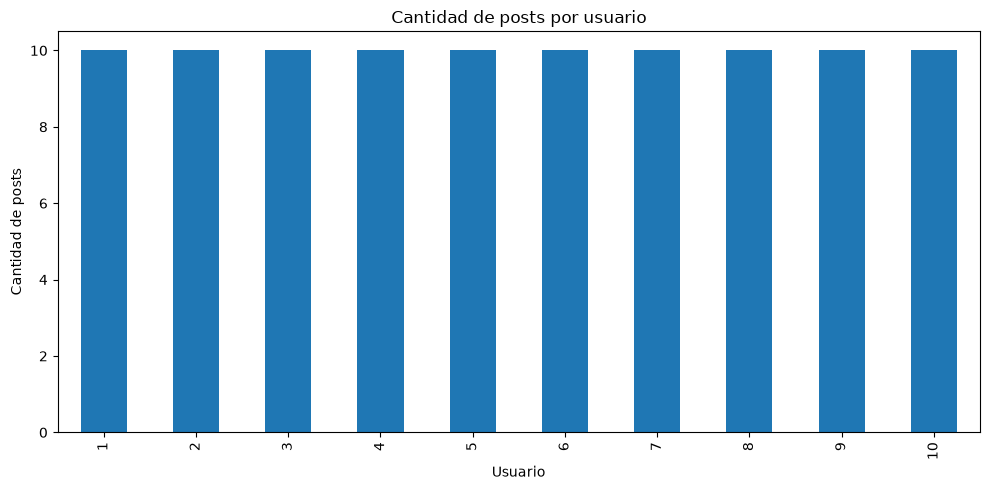

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt


# Obtener los posts
url = "https://jsonplaceholder.typicode.com/posts"

res = requests.get(url)
res.raise_for_status()

datos = res.json()


# Convertir los datos a DataFrame
df = pd.DataFrame(datos)

print("Primeros registros:")
print(df.head())


# Contar cuántos posts tiene cada usuario
posts_por_usuario = df.groupby("userId").size()

print("\nCantidad de posts por usuario:")
print(posts_por_usuario)


# Mostrar cuál usuario tiene más posts
usuario_max = posts_por_usuario.idxmax()
cantidad_max = posts_por_usuario.max()

print(
    f"\nEl usuario {usuario_max} es el que más posts tiene "
    f"con {cantidad_max} posts."
)

# Crear gráfico
posts_por_usuario.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cantidad de posts por usuario")
plt.xlabel("Usuario")
plt.ylabel("Cantidad de posts")

plt.tight_layout()
plt.show()